---
---
## Trabajo Práctico 5 - Estimación de Intervalos
---
---

Considerar $n=32$ lanzamientos de una moneda cargada con probabilidad $p$ de salir cara. El numero de caras $X$ es una variable aleatoria con distribucion binomial $X \sim B(n, p)$. Considerar
un tanda de lanzamientos en el que salen $k$ caras. El estimador del
parametro $p$ es $\hat{p} = \frac{k}{n}$. El intervalo de confianza estándar de $p$ con un nivel de confianza del $95\%$ es $\hat{p} \pm 1.96\sqrt{\hat{p}(1 − \hat{p})/n}$, donde $q = 1.96$ es el cuantil normal estandar para un $95\%$ CL.

  * Simular 10.000 tandas de lanzamientos asumiendo $p = 0.2$.

  * Verificar para cada tanda si el intervalo incluye o no a $p = 0.2$.

  * Estimar la cobertura del intervalo.

  * Decidir si el intervalo es exacto y comparar la cobertura con respecto al nivel de confianza.

  * Barrer $p$ en el intervalo [0,1] en pasos de $0.01$, graficar y ver si hay valores de $p$ para los cuáles la cobertura es particularmente mala.

  * Estimar la cobertura de un nuevo intervalo $t \pm 1.96 \sqrt{t(1 − t)/n}$ con $t = (k + 2)/(n + 4)$, equivalente a “agregar dos  aciertos y dos fracasos”.

In [ ]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.stats import binom

La veriable aleatoria X es el número de caras. Se lanza la moneda cargada 32 veces y se cuenta la cantudad de veces que salió cara y se repite el experimento 10000.

In [ ]:
# Parámetros
n = 32  # número de lanzamientos
p = 0.2 # prob de que salga cara
n_sims = 10000  # cantidad de tandas de lanzamientos para simular

# Simulación de X como variable aleatoria binomial
X = binom.rvs(n, p, size=n_sims, random_state=42)
X[:10]


array([ 6, 10,  8,  7,  4,  4,  3,  9,  7,  8])

In [ ]:
# Calculo del estimador p para cada muestra

p_est = X/n
p_est[:10]

array([0.1875 , 0.3125 , 0.25   , 0.21875, 0.125  , 0.125  , 0.09375,
       0.28125, 0.21875, 0.25   ])

In [ ]:
# Intervalos de confianza (CL = 95%) para cada muestra

q = 1.96
t1 = p_est - q*np.sqrt((p_est*(1 - p_est))/n)
t2 = p_est + q*np.sqrt((p_est*(1 - p_est))/n)

#### Cobertura
Identificamos para cada simulación si el intervalo [t1, t2] **cubre** p=0.2:

In [ ]:
coverage = np.logical_and(t1<p, p<t2)

In [ ]:
import pandas as pd
intervals = pd.DataFrame({"$t_1$": t1, "$t_2$":t2, "Coverage": coverage})
intervals.head(10)

,$t_1$,$t_2$,Coverage
0,0.052264,0.322736,True
1,0.151901,0.473099,True
2,0.099969,0.400031,True
3,0.075515,0.361985,True
4,0.010412,0.239588,True
5,0.010412,0.239588,True
6,-0.007243,0.194743,False
7,0.125468,0.437032,True
8,0.075515,0.361985,True
9,0.099969,0.400031,True


In [ ]:
nhits = coverage.sum()
nhits

np.int64(8882)

In [ ]:
cov_prob = nhits/n_sims
cov_prob

np.float64(0.8882)

La probabilidad de cobertura da 88,5%. Esto quiere decr que en el 88,5% de los 10000 intervalos se cubre el valor verdadero de p. Como la cobertura no es igual al nivel de confianza (CL = 95%), el intervalo no es exacto.

##### Gráfico del estimador medio vs el parámetro p

El primer paso es hacer las 10000 simulaciones pero con 100 valores de p entre 0 y 1.

X_samples es una matriz de 10000 columnas por 100 filas.
Cada fila del arreglo X_samples es una simulación para un valor de p diferente. En el experimento se tirá la moneda 32 veces y se cuanta cuantas veces salió cara, y se repite 10000 veces para cada valor de p. Por ejemplo, la primer fila corresponde a $p = 0$, la segunda a $p=0.01$ y así...

Notar además que la primer fila es 0 porque p = 0 y que la última tiene solo entradas con valor 32 porque p = 1.

(me costó un poco pensar esto, espero que se entienda jaja).

Luego, calculo el estimador $\hat{p} = \frac{X_{samples}}{n}$ (que también será una matriz de 100 filas x 10000 columnas). Para cada simulación calculo el valor medio de $\hat{p}$.

Por último grafico el estimador medio vs p.

In [ ]:
p_values = np.linspace(0, 1, 100)  # 100 valores de p en el intervalo [0, 1]

X_samples = binom.rvs(n, p_values[:, np.newaxis], size=(len(p_values), n_sims))
X_samples[99:100]

array([[32, 32, 32, ..., 32, 32, 32]])

In [ ]:
# Cálculo del estimador
p_est = X_samples / n
print(p_est[:5])

# Cálculo de la media del estimador para cada valor de p
p_est_mean = p_est.mean(axis=1)
print(p_est_mean[:5])

[[0.      0.      0.      ... 0.      0.      0.     ]
 [0.      0.      0.0625  ... 0.      0.03125 0.     ]
 [0.      0.03125 0.03125 ... 0.03125 0.      0.     ]
 [0.0625  0.      0.0625  ... 0.03125 0.      0.03125]
 [0.0625  0.03125 0.      ... 0.09375 0.03125 0.0625 ]]
[0.         0.01023438 0.02008125 0.03019688 0.04025625]


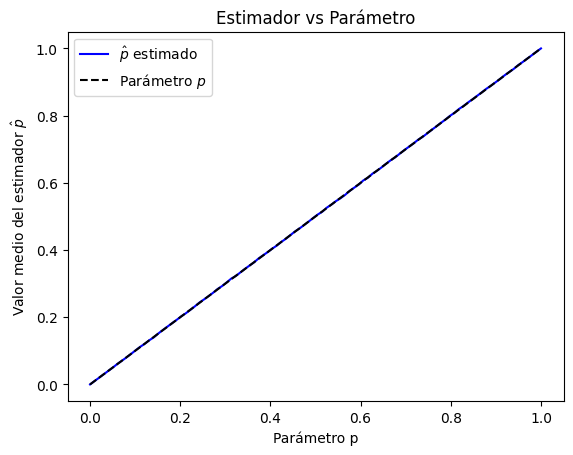

In [ ]:
# Graficar el estimador promedio vs el parámetro p
plt.plot(p_values, p_est_mean, label=r"$\hat{p}$ estimado", color="b")
plt.plot(p_values, p_values, label=r"Parámetro $p$", color="k", linestyle="--")
plt.xlabel("Parámetro p")
plt.ylabel(r"Valor medio del estimador $\hat{p}$")
plt.legend()
plt.title("Estimador vs Parámetro")
plt.show()

#### Cobertura del nuevo intervalo
$t \pm 1.96 \sqrt{t(1 − t)/n}$ con $t = (k + 2)/(n + 4)$

In [ ]:
t = (X+2)/(n+2)
print(t[:10])


t1_2  = t - q*np.sqrt(t*(1-t)/n)
t2_2  = t + q*np.sqrt(t*(1-t)/n)

[0.23529412 0.35294118 0.29411765 0.26470588 0.17647059 0.17647059
 0.14705882 0.32352941 0.26470588 0.29411765]


In [ ]:
coverage2 = np.logical_and(t1_2<0.2, 0.2<t2_2)

intervalos = pd.DataFrame({r"$t_1$": t1_2, r"$t_2$":t2_2, "Coverage2": coverage2})
intervalos.head(10)

,$t_1$,$t_2$,Coverage2
0,0.088322,0.382266,True
1,0.187363,0.518520,True
2,0.136245,0.451991,True
3,0.111846,0.417566,True
4,0.044385,0.308557,True
5,0.044385,0.308557,True
6,0.024347,0.269771,True
7,0.161437,0.485622,True
8,0.111846,0.417566,True
9,0.136245,0.451991,True


In [ ]:
nhits = coverage2.sum()
nhits

np.int64(9554)

In [ ]:
cov_prob2 = nhits/n_sims
cov_prob2

np.float64(0.9554)

La probabilidad de cobertura aumentó a 95,5%. Se observa que al agregar esta corrección obtenemos un intervalo exacto.